# Fig 6 — Optimal treatment across game space, under both H1299 calibrations

Fig. 6 - Optimal treatment across evolutionary game space, under both H1299 calibrations.  
  
Row 1 (A, B): fit including the first day. The (beta, alpha) plane is swept with  
  gamma = 0.7641 and delta = 0.4475 day^-1 fixed. TGF-beta1 changes only alpha, so both  
  H1299 systems lie on the plane.  
Row 2 (C, D): fit excluding the first day (best case H_gamma). The plane is swept with  
  gamma = 0.0082 and delta = 0.5727 day^-1 fixed (untreated estimates). With TGF-beta1 this  
  fit also lowers gamma (to -0.2403), so the +TGF-beta1 star is drawn at its (beta, alpha);  
  its best treatments are also computed at its full parameter set (printed below).  
At each point the dose maximizing J = (R_N/100 + S_L)/2 at T = 15 days (x0 = 0.5,  
N0 = 1e5, K = 1e10) is found for every single intervention (A, C) and every pair (B, D).  
Single agents: 21 doses; pairs: 21 x 21 dose grid. Runtime: about 25 minutes  
(set USE_CACHE = True to reuse maps saved by an earlier run).  
Output: ../figures/Fig6_optimal_treatment_game_space.png / .pdf

## Settings and fitted values
Set `USE_CACHE = False` to recompute the maps from scratch (about 25 minutes). With `True`, the maps saved in `Fig6_maps_cache.npz` are reused.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from lf_model import simulate, TARGETS, TARGET_LABEL, set_style, save

set_style()
USE_CACHE = True
CACHE = "Fig6_maps_cache.npz"
T, dt, X0 = 15.0, 0.05, 0.5
FITS = {   # gamma, delta fixed on the plane; beta; alpha and gamma for each condition
    "incl": dict(name="Fit including the first day ($H_0$)", gamma=0.7641, delta=0.4475, beta=0.1232,
                 alpha={"untreated": 0.3796, "TGF": 0.1212}, gam={"untreated": 0.7641, "TGF": 0.7641}),
    "excl": dict(name="Fit excluding the first day ($H_\\gamma$)", gamma=0.0082, delta=0.5727, beta=-0.1457,
                 alpha={"untreated": 0.3656, "TGF": 0.0811}, gam={"untreated": 0.0082, "TGF": -0.2403}),
}
n_grid = 61
bv = np.linspace(-0.5, 1.4, n_grid)
av = np.linspace(0.0, 1.5, n_grid)
B, A = np.meshgrid(bv, av)
pairs = list(combinations(TARGETS, 2))

## Model outcome and dose optimization
$J = \tfrac12(R_N/100 + S_L)$ at $T = 15$ days. Single agents: 21 doses; pairs: 21 × 21 doses.

In [2]:
def outcome(a, b, g, de, doses):
    p = {"alpha": a, "beta": b, "gamma": g, "delta": de}
    q = {k: (1 - np.asarray(doses.get(k, 0.0))) * v for k, v in p.items()}
    _, n_u = simulate(a, b, g, de, x0=X0, T=T, dt=dt)
    x_t, n_t = simulate(q["alpha"], q["beta"], q["gamma"], q["delta"], x0=X0, T=T, dt=dt)
    return 0.5 * ((n_u - n_t) / n_u + (1 - x_t))

def best_over_doses(J, a):
    lead = J.ndim - np.ndim(a)
    return J.reshape(-1, *J.shape[lead:]).max(0) if lead else J

def maps(g, de):
    d1 = np.linspace(0, 1, 21)[:, None, None]; d2 = np.linspace(0, 1, 21)
    s = np.stack([best_over_doses(outcome(A, B, g, de, {t: d1}), A) for t in TARGETS])
    pj = np.stack([best_over_doses(outcome(A, B, g, de, {p: d2[:, None, None, None], q: d2[None, :, None, None]}), A)
                   for p, q in pairs])
    return s.argmax(0), pj.argmax(0)

## Maps for both calibrations

In [3]:
if USE_CACHE and os.path.exists(CACHE):
    M = dict(np.load(CACHE))
else:
    M = {}
    for key, f in FITS.items():
        M[key + "_s"], M[key + "_p"] = maps(f["gamma"], f["delta"])
    np.savez(CACHE, **M)

## Share of the plane for each treatment, and the H1299 points
Each H1299 point is evaluated at its full parameter set (including $\gamma=-0.24$ for +TGF-β1 in the fit excluding the first day).

In [4]:
for key, f in FITS.items():
    print(f"\n{f['name']}  (gamma = {f['gamma']}, delta = {f['delta']})")
    print("  single: " + ", ".join(f"{t} {100*np.mean(M[key+'_s']==k):.0f}%" for k, t in enumerate(TARGETS)))
    print("  pairs:  " + ", ".join(f"{p}+{q} {100*np.mean(M[key+'_p']==k):.0f}%" for k, (p, q) in enumerate(pairs)))
    for cond in ("untreated", "TGF"):        # each H1299 point at its full parameter set
        a, b, g, de = f["alpha"][cond], f["beta"], f["gam"][cond], f["delta"]
        d = np.linspace(0, 1, 101); dd = np.linspace(0, 1, 41)
        js = {t: outcome(np.array(a), np.array(b), g, de, {t: d}) for t in TARGETS}
        jp = {pq: outcome(np.array(a), np.array(b), g, de, {pq[0]: dd[:, None], pq[1]: dd[None, :]}) for pq in pairs}
        sb = max(js, key=lambda k: js[k].max()); pr = sorted(jp, key=lambda k: -jp[k].max())
        i, j = np.unravel_index(jp[pr[0]].argmax(), jp[pr[0]].shape)
        print(f"  H1299 {cond:9s}: best single {sb} (d = {d[js[sb].argmax()]:.2f}, J = {js[sb].max():.3f}); "
              f"best pair {pr[0][0]}+{pr[0][1]} (d = {dd[i]:.2f}, {dd[j]:.2f}, J = {jp[pr[0]].max():.3f}); "
              f"2nd {pr[1][0]}+{pr[1][1]} (J = {jp[pr[1]].max():.3f})")


Fit including the first day ($H_0$)  (gamma = 0.7641, delta = 0.4475)
  single: alpha 23%, beta 45%, gamma 3%, delta 30%
  pairs:  alpha+beta 33%, alpha+gamma 2%, alpha+delta 30%, beta+gamma 0%, beta+delta 34%, gamma+delta 1%


  H1299 untreated: best single delta (d = 0.52, J = 0.900); best pair beta+delta (d = 1.00, 0.60, J = 0.957); 2nd alpha+delta (J = 0.946)


  H1299 TGF      : best single delta (d = 0.58, J = 0.933); best pair beta+delta (d = 1.00, 0.65, J = 0.969); 2nd alpha+delta (J = 0.943)

Fit excluding the first day ($H_\gamma$)  (gamma = 0.0082, delta = 0.5727)
  single: alpha 59%, beta 14%, gamma 0%, delta 26%
  pairs:  alpha+beta 42%, alpha+gamma 0%, alpha+delta 33%, beta+gamma 1%, beta+delta 23%, gamma+delta 0%


  H1299 untreated: best single delta (d = 0.41, J = 0.979); best pair alpha+delta (d = 1.00, 0.60, J = 0.990); 2nd beta+delta (J = 0.979)


  H1299 TGF      : best single delta (d = 0.43, J = 0.985); best pair alpha+delta (d = 1.00, 0.48, J = 0.988); 2nd gamma+delta (J = 0.986)


## Figure

Saved ../figures/Fig6_optimal_treatment_game_space.png/.pdf


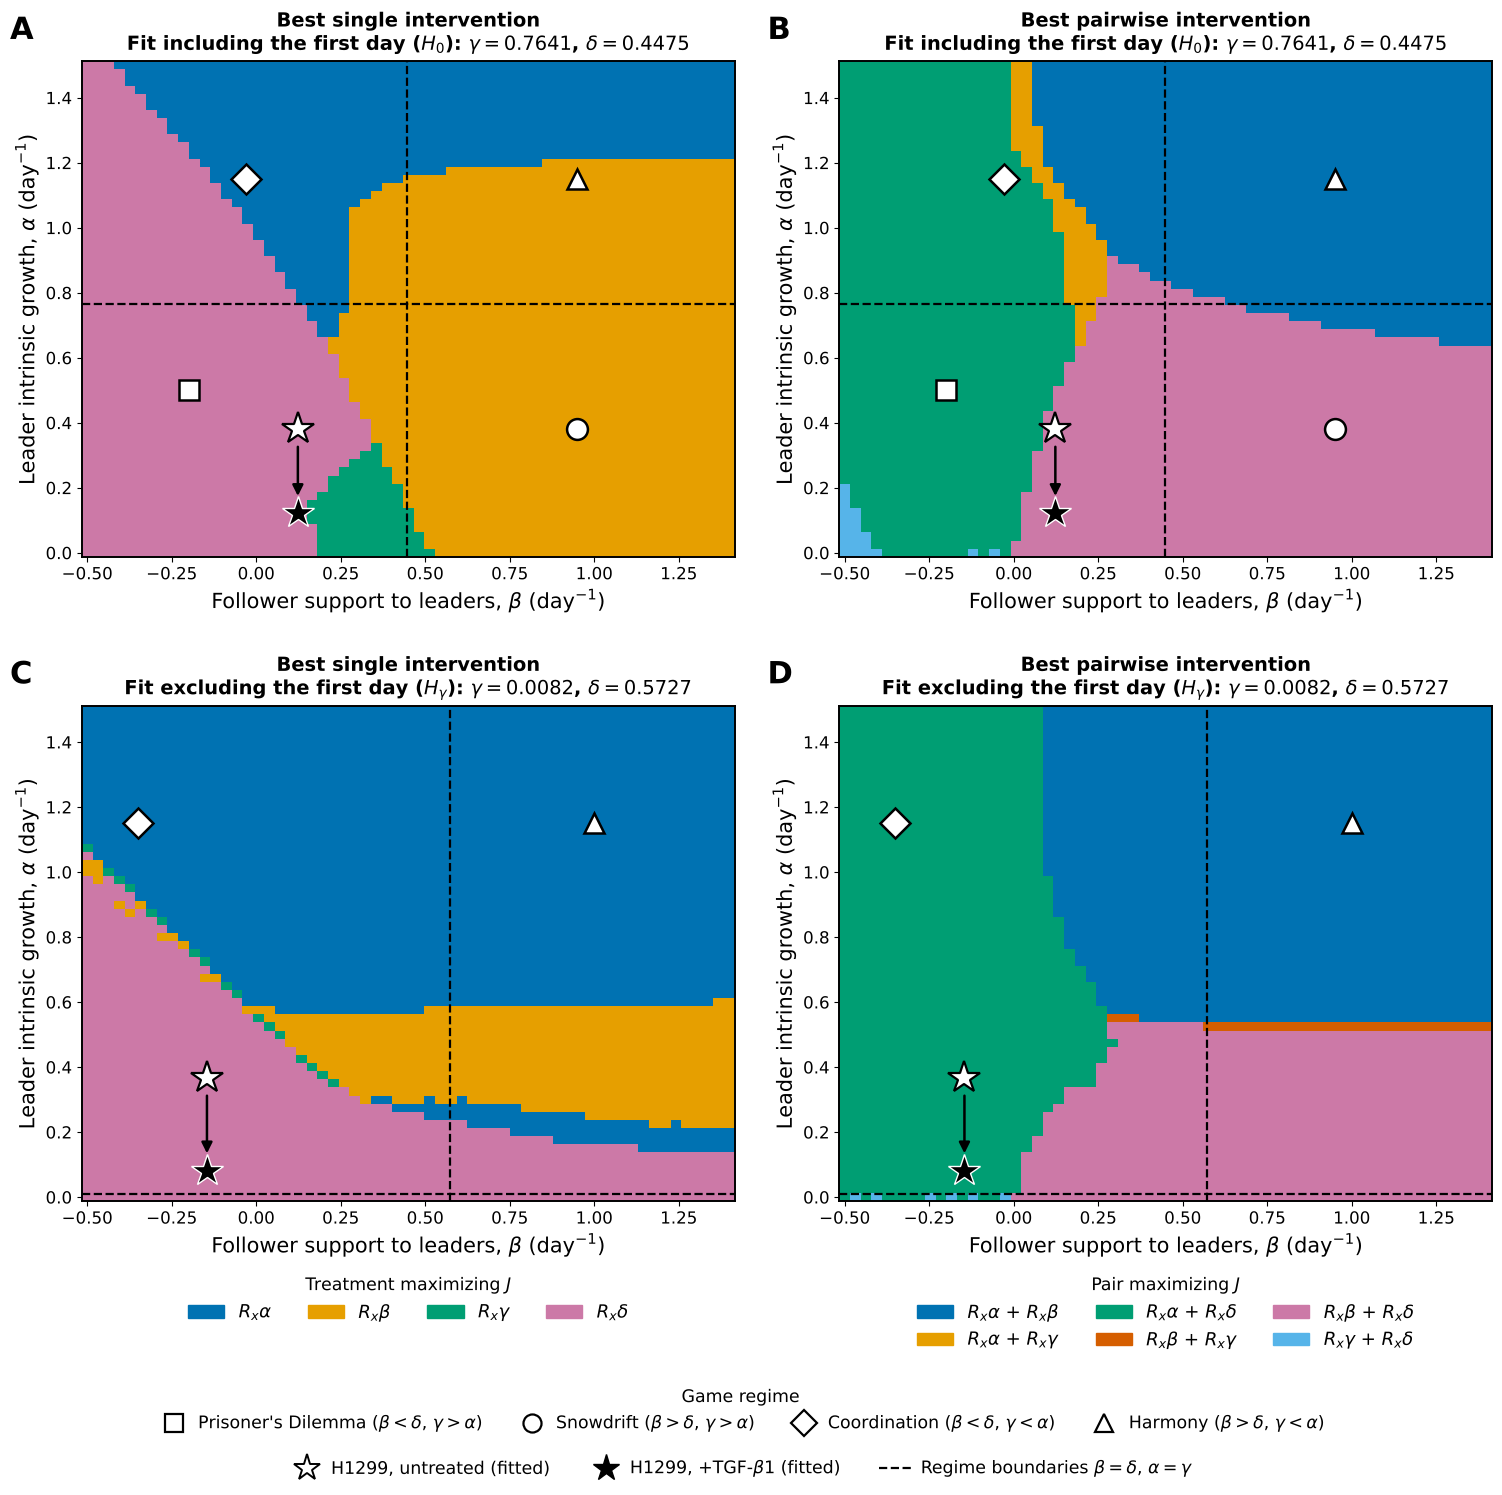

In [5]:
%matplotlib inline
single_cols = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
pair_cols = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
MK = {"PD": "s", "SD": "o", "CO": "D", "HA": "^"}
GAME_LAB = {"PD": "Prisoner's Dilemma ($\\beta<\\delta$, $\\gamma>\\alpha$)",
            "SD": "Snowdrift ($\\beta>\\delta$, $\\gamma>\\alpha$)",
            "CO": "Coordination ($\\beta<\\delta$, $\\gamma<\\alpha$)",
            "HA": "Harmony ($\\beta>\\delta$, $\\gamma<\\alpha$)"}
GAME_POS = {"incl": {"PD": (-0.20, 0.50), "SD": (0.95, 0.38), "CO": (-0.03, 1.15), "HA": (0.95, 1.15)},
            "excl": {"CO": (-0.35, 1.15), "HA": (1.00, 1.15)}}   # PD/SD only below alpha = gamma = 0.008
ext = [bv[0] - (bv[1] - bv[0]) / 2, bv[-1] + (bv[1] - bv[0]) / 2,
       av[0] - (av[1] - av[0]) / 2, av[-1] + (av[1] - av[0]) / 2]
fig, axes = plt.subplots(2, 2, figsize=(15.5, 15.0))
fig.subplots_adjust(left=0.075, right=0.985, top=0.955, bottom=0.195, wspace=0.16, hspace=0.30)
letters = iter("ABCD")
for r, (key, f) in enumerate(FITS.items()):
    for c, (data, cols, labels, title) in enumerate([
            (M[key + "_s"], single_cols, [TARGET_LABEL[t] for t in TARGETS], "Best single intervention"),
            (M[key + "_p"], pair_cols, [f"{TARGET_LABEL[p]} + {TARGET_LABEL[q]}" for p, q in pairs],
             "Best pairwise intervention")]):
        ax = axes[r, c]
        ax.imshow(data, origin="lower", extent=ext, cmap=ListedColormap(cols), vmin=-0.5,
                  vmax=len(cols) - 0.5, interpolation="nearest", aspect="auto")
        ax.axvline(f["delta"], color="k", ls="--", lw=1.6); ax.axhline(f["gamma"], color="k", ls="--", lw=1.6)
        for g, (xx, yy) in GAME_POS[key].items():
            ax.plot(xx, yy, MK[g], ms=15, mfc="white", mec="k", mew=1.8)
        a_u, a_t, b = f["alpha"]["untreated"], f["alpha"]["TGF"], f["beta"]
        ax.annotate("", xy=(b, a_t + 0.045), xytext=(b, a_u - 0.045),
                    arrowprops=dict(arrowstyle="-|>", color="k", lw=1.8, mutation_scale=16))
        ax.plot(b, a_u, "*", ms=24, mfc="white", mec="k", mew=1.6, zorder=6)
        ax.plot(b, a_t, "*", ms=24, mfc="k", mec="white", mew=1.0, zorder=6)
        ax.set_xlim(ext[:2]); ax.set_ylim(ext[2:])
        ax.set_xlabel(r"Follower support to leaders, $\beta$ (day$^{-1}$)", fontsize=15)
        ax.set_ylabel(r"Leader intrinsic growth, $\alpha$ (day$^{-1}$)", fontsize=15)
        ax.set_title(f"{title}\n{f['name']}: $\\gamma={f['gamma']}$, $\\delta={f['delta']}$",
                     fontsize=14, fontweight="bold", pad=8)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(True)
        ax.text(-0.11, 1.03, next(letters), transform=ax.transAxes, fontsize=22, fontweight="bold", va="bottom")
        if r == 1:
            ax.legend(handles=[Patch(color=cc, label=l) for cc, l in zip(cols, labels)], loc="upper center",
                      bbox_to_anchor=(0.5, -0.12), ncol=3 if len(cols) > 4 else 4, frameon=False, fontsize=13,
                      title="Treatment maximizing $J$" if c == 0 else "Pair maximizing $J$", title_fontsize=12.5)
g_handles = [Line2D([], [], marker=MK[g], ls="none", ms=13, mfc="white", mec="k", mew=1.6, label=GAME_LAB[g])
             for g in ("PD", "SD", "CO", "HA")]
h_handles = [Line2D([], [], marker="*", ls="none", ms=20, mfc="white", mec="k", mew=1.4, label="H1299, untreated (fitted)"),
             Line2D([], [], marker="*", ls="none", ms=20, mfc="k", mec="k", label="H1299, +TGF-$\\beta$1 (fitted)"),
             Line2D([], [], color="k", ls="--", lw=1.6, label="Regime boundaries $\\beta=\\delta$, $\\alpha=\\gamma$")]
fig.legend(handles=g_handles, loc="lower center", bbox_to_anchor=(0.5, 0.03), ncol=4, frameon=False,
           fontsize=12.5, columnspacing=1.8, handletextpad=0.4, title="Game regime", title_fontsize=12.5)
fig.legend(handles=h_handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False,
           fontsize=12.5, columnspacing=2.2, handletextpad=0.4)
save(fig, "Fig6_optimal_treatment_game_space", outdir="../figures")
plt.show()